# 04 · El Niño y La Niña (índice ONI) frente al fuego en la Altillanura

**Fuente:** NOAA Climate Prediction Center, Oceanic Niño Index (ONI),
promedio móvil de 3 meses de la anomalía de temperatura en la región
Niño 3.4.

**Propósito:** clasificar los meses en El Niño, La Niña o neutral, y
comprobar si las temporadas de fuego con El Niño tienen más detecciones.

**Entradas:** ONI (NOAA) y `firms_mensual_municipio.csv` (notebook 03).

**Salidas:** `oni_mensual.csv` y `fuego_oni_temporadas.csv`.

## Paso 1. Preparar el entorno

In [1]:
from google.colab import drive
drive.mount('/content/drive')

RUTA = '/content/drive/MyDrive/proyecto-altillanura-STDG'
CRUDOS = f'{RUTA}/datos/crudos'
PROCESADOS = f'{RUTA}/datos/procesados'
FIGURAS = f'{RUTA}/resultados/figuras'

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

print('Entorno listo')

Mounted at /content/drive
Entorno listo


## Paso 2. Descargar el ONI desde NOAA
Se guarda una copia en `datos/crudos/noaa/` para no depender de la web.

In [2]:
URL = 'https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt'
carpeta_noaa = f'{CRUDOS}/noaa'
os.makedirs(carpeta_noaa, exist_ok=True)
copia = f'{carpeta_noaa}/oni.ascii.txt'

try:
    oni_raw = pd.read_csv(URL, sep=r'\s+')
    oni_raw.to_csv(copia, sep=' ', index=False)
    print('Descargado desde NOAA y guardado en Drive')
except Exception as e:
    print('No se pudo descargar desde NOAA:', e)
    oni_raw = pd.read_csv(copia, sep=r'\s+')
    print('Se usó la copia guardada en Drive')

print('Columnas:', list(oni_raw.columns))
print('Desde', oni_raw.iloc[0]['SEAS'], oni_raw.iloc[0]['YR'],
      'hasta', oni_raw.iloc[-1]['SEAS'], oni_raw.iloc[-1]['YR'])
oni_raw.tail()

Descargado desde NOAA y guardado en Drive
Columnas: ['SEAS', 'YR', 'TOTAL', 'ANOM']
Desde DJF 1950 hasta ASO 2026


,SEAS,YR,TOTAL,ANOM
916,AMJ,2026,28.74,0.95
917,MJJ,2026,29.02,1.39
918,JJA,2026,29.09,1.80
919,JAS,2026,29.12,2.16
920,ASO,2026,29.23,2.46


## Paso 3. Asignar cada valor a su mes y clasificar las fases
Cada periodo de 3 meses se asigna a su mes central (DJF → enero).
Regla de NOAA: El Niño (La Niña) = al menos 5 periodos seguidos con
ONI ≥ +0,5 (≤ −0,5).

In [3]:
CENTRO = {'DJF': 1, 'JFM': 2, 'FMA': 3, 'MAM': 4, 'AMJ': 5, 'MJJ': 6,
          'JJA': 7, 'JAS': 8, 'ASO': 9, 'SON': 10, 'OND': 11, 'NDJ': 12}

oni = oni_raw.copy()
oni['mes_num'] = oni['SEAS'].map(CENTRO)
oni['fecha'] = pd.to_datetime(dict(year=oni['YR'], month=oni['mes_num'], day=1))
oni = (oni.rename(columns={'ANOM': 'oni'})[['fecha', 'SEAS', 'oni']]
          .set_index('fecha').sort_index())

def episodio(cond, minimo=5):
    """True solo en rachas de al menos `minimo` meses seguidos."""
    grupo = (cond != cond.shift()).cumsum()
    largo = cond.groupby(grupo).transform('sum')
    return cond & (largo >= minimo)

nino = episodio(oni['oni'] >= 0.5)
nina = episodio(oni['oni'] <= -0.5)
oni['fase'] = 'Neutral'
oni.loc[nino, 'fase'] = 'El Niño'
oni.loc[nina, 'fase'] = 'La Niña'

print('Meses por fase, 2003–2025:')
print(oni.loc['2003':'2025', 'fase'].value_counts().to_string())

print('\nEpisodios de El Niño desde 2000 (inicio – fin, pico):')
sub = oni.loc['2000':]
grupos = (sub['fase'] != sub['fase'].shift()).cumsum()
for _, g in sub[sub['fase'] == 'El Niño'].groupby(grupos):
    print(f"  {g.index[0]:%Y-%m} – {g.index[-1]:%Y-%m}   pico ONI = {g['oni'].max():+.1f}")

Meses por fase, 2003–2025:
fase
Neutral    136
El Niño     70
La Niña     70

Episodios de El Niño desde 2000 (inicio – fin, pico):
  2002-07 – 2003-02   pico ONI = +1.2
  2004-08 – 2005-02   pico ONI = +0.7
  2006-09 – 2007-01   pico ONI = +0.9
  2009-07 – 2010-03   pico ONI = +1.5
  2014-10 – 2016-05   pico ONI = +2.6
  2018-09 – 2019-06   pico ONI = +1.1
  2019-10 – 2020-03   pico ONI = +0.8
  2023-06 – 2024-04   pico ONI = +2.0
  2026-05 – 2026-09   pico ONI = +2.5


## Paso 4. Gráfico del ONI, 2000–2025

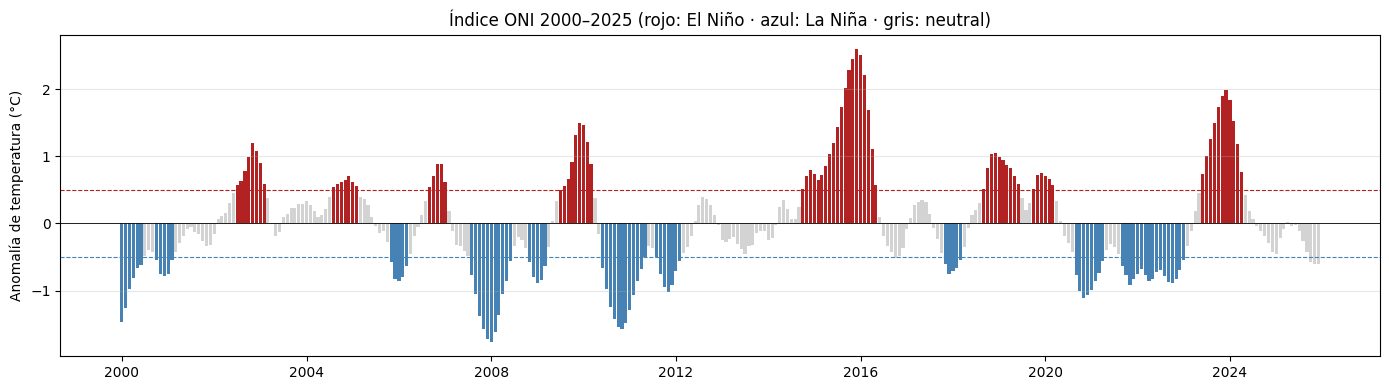

In [4]:
o = oni.loc['2000':'2025']
colores = o['fase'].map({'El Niño': 'firebrick', 'La Niña': 'steelblue',
                         'Neutral': 'lightgray'})

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(o.index, o['oni'], width=25, color=colores)
ax.axhline(0.5, color='firebrick', linestyle='--', linewidth=0.8)
ax.axhline(-0.5, color='steelblue', linestyle='--', linewidth=0.8)
ax.axhline(0, color='black', linewidth=0.6)
ax.set_title('Índice ONI 2000–2025 (rojo: El Niño · azul: La Niña · gris: neutral)')
ax.set_ylabel('Anomalía de temperatura (°C)')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/04_oni_2000_2025.png', dpi=150)
plt.show()

## Paso 5. Temporadas de fuego y ONI
Temporada de fuego del año *y* = diciembre de *y−1* a marzo de *y*
(concentra el 77 % de las detecciones). Se usa Terra + Aqua desde 2003.
ONI de la temporada = promedio de noviembre de *y−1* a febrero de *y*.

In [5]:
mens = pd.read_csv(f'{PROCESADOS}/firms_mensual_municipio.csv',
                   dtype={'mpio_cdpmp': str})
mens['fecha'] = pd.PeriodIndex(mens['mes'], freq='M').to_timestamp()
region = mens.groupby('fecha')['focos_total'].sum().loc['2003-01-01':]

# Detecciones por temporada (dic–mar), solo temporadas completas
t = region[region.index.month.isin([12, 1, 2, 3])]
anio_t = np.where(t.index.month == 12, t.index.year + 1, t.index.year)
focos_temp = t.groupby(anio_t).sum()
meses_temp = t.groupby(anio_t).size()
focos_temp = focos_temp[meses_temp == 4]

# ONI promedio de la temporada (nov–feb)
o = oni['oni']
o = o[o.index.month.isin([11, 12, 1, 2])]
anio_o = np.where(o.index.month >= 11, o.index.year + 1, o.index.year)
oni_temp = o.groupby(anio_o).mean()

tabla = pd.DataFrame({'focos_temporada': focos_temp,
                      'oni_nov_feb': oni_temp}).dropna()
tabla.index.name = 'temporada'
tabla['fase'] = np.select([tabla['oni_nov_feb'] >= 0.5,
                           tabla['oni_nov_feb'] <= -0.5],
                          ['El Niño', 'La Niña'], default='Neutral')

print('Temporadas analizadas:', tabla.index.min(), '–', tabla.index.max(),
      f'({len(tabla)} temporadas)')
print(tabla.round(2).to_string())

Temporadas analizadas: 2004 – 2025 (22 temporadas)
           focos_temporada  oni_nov_feb     fase
temporada                                       
2004               11574.0         0.30  Neutral
2005                6105.0         0.63  El Niño
2006                6042.0        -0.76  La Niña
2007               11426.0         0.64  El Niño
2008                7185.0        -1.66  La Niña
2009                5164.0        -0.77  La Niña
2010                7921.0         1.37  El Niño
2011                5520.0        -1.35  La Niña
2012                4647.0        -0.80  La Niña
2013                6353.0        -0.11  Neutral
2014                8245.0        -0.17  Neutral
2015                4866.0         0.72  El Niño
2016                7637.0         2.44  El Niño
2017                5000.0        -0.22  Neutral
2018                8103.0        -0.69  La Niña
2019                6185.0         1.00  El Niño
2020                8982.0         0.71  El Niño
2021              

## Paso 6. ¿Las temporadas con El Niño tienen más fuego?

Correlación de Pearson:  r = +0.26  (p = 0.251)
Correlación de Spearman: ρ = +0.33  (p = 0.135)

Detecciones promedio por temporada según la fase:
         count    mean  median
fase                          
El Niño      8  7337.0  6911.0
La Niña      9  6148.0  6042.0
Neutral      5  7170.0  6353.0


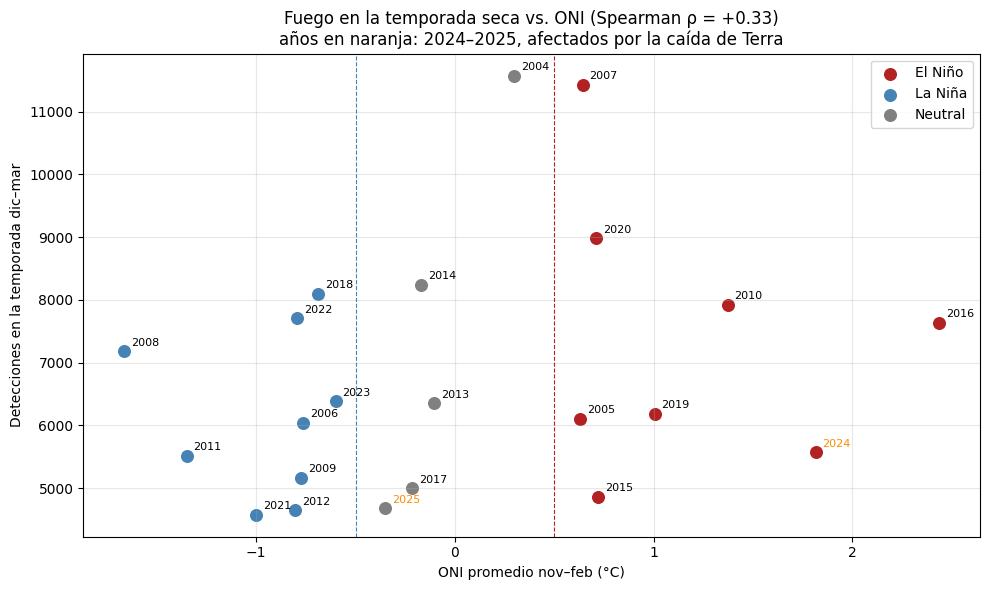

In [6]:
r_p, p_p = stats.pearsonr(tabla['oni_nov_feb'], tabla['focos_temporada'])
r_s, p_s = stats.spearmanr(tabla['oni_nov_feb'], tabla['focos_temporada'])
print(f'Correlación de Pearson:  r = {r_p:+.2f}  (p = {p_p:.3f})')
print(f'Correlación de Spearman: ρ = {r_s:+.2f}  (p = {p_s:.3f})')

print('\nDetecciones promedio por temporada según la fase:')
print(tabla.groupby('fase')['focos_temporada']
      .agg(['count', 'mean', 'median']).round(0).to_string())

colores = {'El Niño': 'firebrick', 'La Niña': 'steelblue', 'Neutral': 'gray'}
fig, ax = plt.subplots(figsize=(10, 6))
for fase, g in tabla.groupby('fase'):
    ax.scatter(g['oni_nov_feb'], g['focos_temporada'], s=70,
               color=colores[fase], label=fase)
for anio, fila in tabla.iterrows():
    ax.annotate(str(anio), (fila['oni_nov_feb'], fila['focos_temporada']),
                xytext=(5, 4), textcoords='offset points', fontsize=8,
                color='darkorange' if anio >= 2024 else 'black')
ax.axvline(0.5, color='firebrick', linestyle='--', linewidth=0.8)
ax.axvline(-0.5, color='steelblue', linestyle='--', linewidth=0.8)
ax.set_xlabel('ONI promedio nov–feb (°C)')
ax.set_ylabel('Detecciones en la temporada dic–mar')
ax.set_title(f'Fuego en la temporada seca vs. ONI (Spearman ρ = {r_s:+.2f})\n'
             'años en naranja: 2024–2025, afectados por la caída de Terra')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIGURAS}/04_fuego_vs_oni.png', dpi=150)
plt.show()

## Paso 7. Correlación mes a mes con rezagos
Se quita la estacionalidad (anomalías del logaritmo respecto al promedio
de cada mes) y se mide la correlación con el ONI de 0 a 12 meses antes.

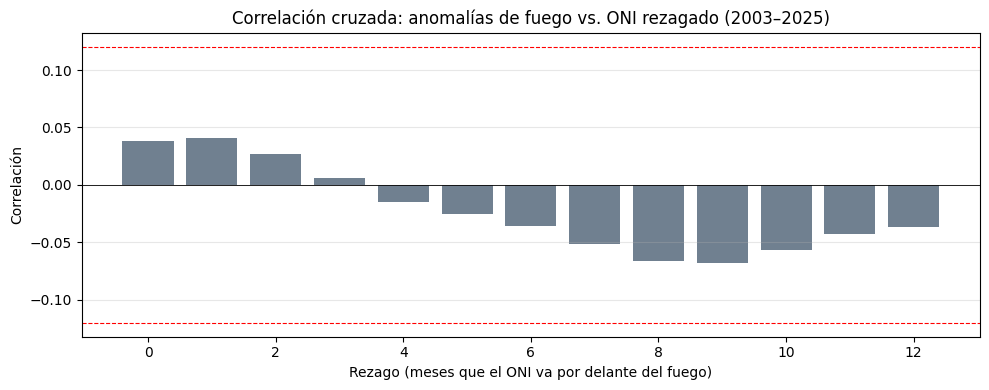

Rezago con mayor correlación: 9 meses (r = -0.07); banda de significancia ±0.12


In [7]:
log_f = np.log1p(region)
clim = log_f.groupby(log_f.index.month).transform('mean')
anom = log_f - clim

oni_m = oni['oni'].reindex(anom.index.union(oni.index)).sort_index()
rezagos = range(0, 13)
corr = [anom.corr(oni_m.shift(k).reindex(anom.index)) for k in rezagos]

limite = 2 / np.sqrt(len(anom))   # banda aproximada de significancia al 5 %

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(list(rezagos), corr, color='slategray')
ax.axhline(limite, color='red', linestyle='--', linewidth=0.8)
ax.axhline(-limite, color='red', linestyle='--', linewidth=0.8)
ax.axhline(0, color='black', linewidth=0.6)
ax.set_xlabel('Rezago (meses que el ONI va por delante del fuego)')
ax.set_ylabel('Correlación')
ax.set_title('Correlación cruzada: anomalías de fuego vs. ONI rezagado (2003–2025)')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/04_correlacion_cruzada_oni.png', dpi=150)
plt.show()

mejor = int(np.argmax(np.abs(corr)))
print(f'Rezago con mayor correlación: {mejor} meses (r = {corr[mejor]:+.2f}); '
      f'banda de significancia ±{limite:.2f}')

## Paso 8. Guardar resultados

In [8]:
oni.reset_index().to_csv(f'{PROCESADOS}/oni_mensual.csv', index=False)
tabla.reset_index().to_csv(f'{PROCESADOS}/fuego_oni_temporadas.csv', index=False)

print('Guardado OK |', len(oni), 'meses de ONI |', len(tabla), 'temporadas')

Guardado OK | 921 meses de ONI | 22 temporadas
